# 0. Veri Seti Keşfi ve Ön İnceleme (Exploratory Data Analysis - EDA)
Bu aşamada veri setinin yapısal özellikleri, eksik veri (missing value) durumu ve temel istatistiksel özetleri incelenmiştir.

In [4]:
import pandas as pd
import numpy as np

# Örnek detaylı ham veri seti simülasyonu
ham_veri = {
    'Siparis_ID': [1001, 1002, 1003, 1004, 1005, 1006, 1007],
    'Kategori': ['Elektronik', 'Aksesuar', 'Elektronik', 'Ofis', 'Aksesuar', 'Elektronik', 'Ofis'],
    'Fiyat': [4500, 320, 2700, 150, 450, 12000, 850],
    'Adet': [2, 5, 1, 10, 3, 1, 4],
    'Musteri_Puani': [4.8, 4.2, np.nan, 3.9, 4.5, 5.0, 4.1] # Bilerek eksik veri (NaN) koyduk
}

df_ham = pd.DataFrame(ham_veri)

# 1. İlk 5 satırı görüntüleme
print("--- Veri Setinin İlk Satırları ---")
print(df_ham.head())

# 2. Eksik veri kontrolü (Analist refleksi)
print("\n--- Eksik Değer Kontrolü ---")
print(df_ham.isnull().sum())

# 3. İstatistiksel Özet (Ortalama, min, max, standart sapma)
print("\n--- Sayısal Verilerin İstatistiksel Özeti ---")
print(df_ham.describe().T[['mean', 'std', 'min', 'max']])

--- Veri Setinin İlk Satırları ---
   Siparis_ID    Kategori  Fiyat  Adet  Musteri_Puani
0        1001  Elektronik   4500     2            4.8
1        1002    Aksesuar    320     5            4.2
2        1003  Elektronik   2700     1            NaN
3        1004        Ofis    150    10            3.9
4        1005    Aksesuar    450     3            4.5

--- Eksik Değer Kontrolü ---
Siparis_ID       0
Kategori         0
Fiyat            0
Adet             0
Musteri_Puani    1
dtype: int64

--- Sayısal Verilerin İstatistiksel Özeti ---
                      mean          std     min      max
Siparis_ID     1004.000000     2.160247  1001.0   1007.0
Fiyat          2995.714286  4277.261028   150.0  12000.0
Adet              3.714286     3.147183     1.0     10.0
Musteri_Puani     4.416667     0.426224     3.9      5.0


# 1. Ürün Bazında Gelir ve Ciro Analizi
Bu bölümde işletmenin en çok gelir getiren ürün kategorileri tespit edilmiş ve karar vericiler için görselleştirilmiştir.

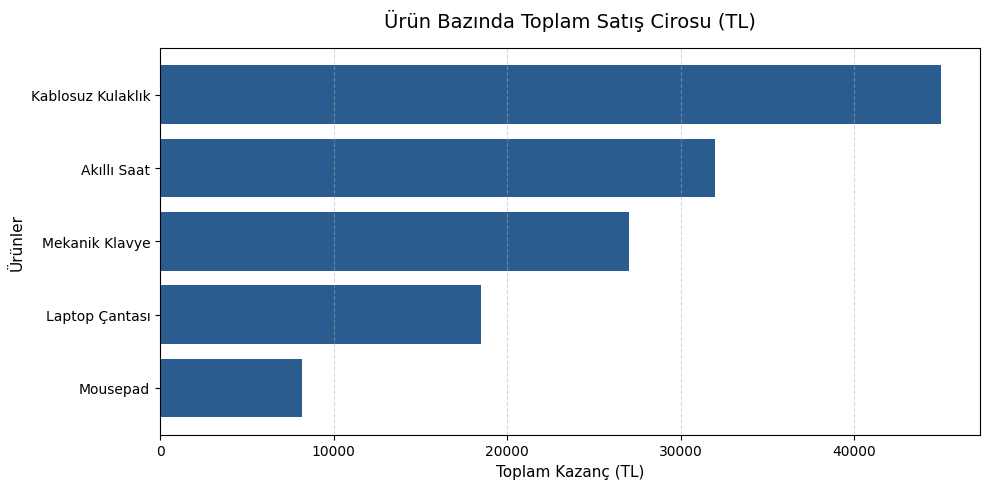

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Satış verimizi tanımlıyoruz
veri = {
    'urun_adi': ['Kablosuz Kulaklık', 'Akıllı Saat', 'Laptop Çantası', 'Mekanik Klavye', 'Mousepad'],
    'toplam_kazanc': [45000, 32000, 18500, 27000, 8200]
}

# 2. Veriyi tabloya çevirip kazanca göre sıralıyoruz
df = pd.DataFrame(veri)
df = df.sort_values(by='toplam_kazanc', ascending=True)

# 3. Grafiği çizdiriyoruz
plt.figure(figsize=(10, 5))
plt.barh(df['urun_adi'], df['toplam_kazanc'], color='#2b5c8f')

plt.title('Ürün Bazında Toplam Satış Cirosu (TL)', fontsize=14, pad=15)
plt.xlabel('Toplam Kazanç (TL)', fontsize=11)
plt.ylabel('Ürünler', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 2. 2025 Yılı Satış Trendi ve Zaman Serisi İncelemesi
Bu bölümde aylık satış performansındaki dalgalanmalar ve büyüme trendi analiz edilmiştir.

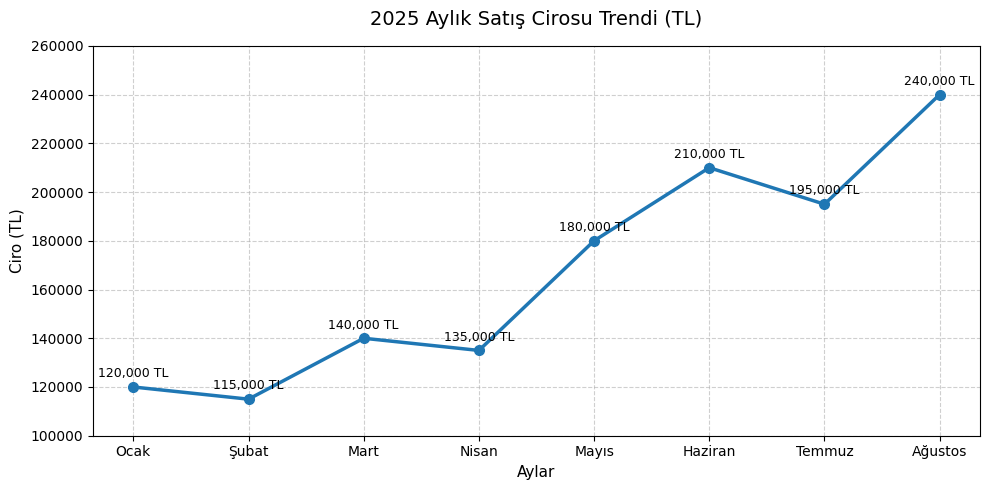

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 2025 yılı aylık satış cirosu ve sipariş adedi verimiz
aylik_veri = {
    'Ay': ['Ocak', 'Şubat', 'Mart', 'Nisan', 'Mayıs', 'Haziran', 'Temmuz', 'Ağustos'],
    'Ciro_TL': [120000, 115000, 140000, 135000, 180000, 210000, 195000, 240000]
}

df_trend = pd.DataFrame(aylik_veri)

# 2. Çizgi Grafiği (Line Plot) Çizimi
plt.figure(figsize=(10, 5))
plt.plot(df_trend['Ay'], df_trend['Ciro_TL'], marker='o', color='#1f77b4', linewidth=2.5, markersize=7)

# 3. Görsel İyileştirmeler
plt.title('2025 Aylık Satış Cirosu Trendi (TL)', fontsize=14, pad=15)
plt.xlabel('Aylar', fontsize=11)
plt.ylabel('Ciro (TL)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

# Grafikteki noktaların üzerine değerleri yazdırma (Profesyonel dokunuş)
for i, txt in enumerate(df_trend['Ciro_TL']):
    plt.annotate(f"{txt:,} TL", (df_trend['Ay'][i], df_trend['Ciro_TL'][i] + 4000), ha='center', fontsize=9)

plt.ylim(100000, 260000)
plt.tight_layout()
plt.show()

# 3. Müşteri Tutundurma ve Kayıp (Churn) Dağılımı
Bu bölümde mevcut müşteri tabanının sadakat durumu incelenmiş, terk riski taşıyan (churn) ve aktif olan kullanıcı oranları hesaplanmıştır.

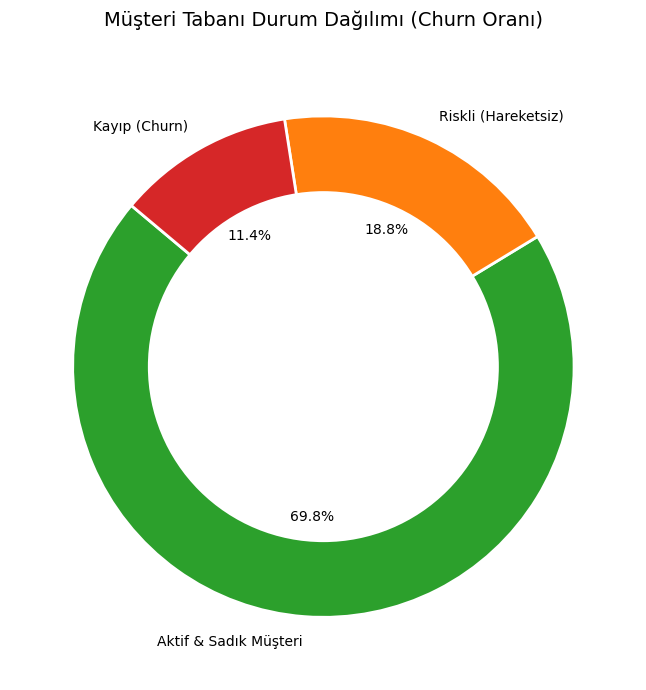

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Müşteri segmenti ve churn (kayıp) dağılım verimiz
musteri_durumu = {
    'Durum': ['Aktif & Sadık Müşteri', 'Riskli (Hareketsiz)', 'Kayıp (Churn)'],
    'Musteri_Sayisi': [5200, 1400, 850]
}

df_churn = pd.DataFrame(musteri_durumu)

# 2. Modern Halka Grafik (Donut Chart) Çizimi
renkler = ['#2ca02c', '#ff7f0e', '#d62728'] # Yeşil, Turuncu, Kırmızı

plt.figure(figsize=(7, 7))
plt.pie(
    df_churn['Musteri_Sayisi'],
    labels=df_churn['Durum'],
    autopct='%1.1f%%',
    startangle=140,
    colors=renkler,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

# Ortasını delerek pasta grafiği halka grafiğe dönüştürme (Modern analist dokunuşu)
merkez_cemberi = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(merkez_cemberi)

plt.title('Müşteri Tabanı Durum Dağılımı (Churn Oranı)', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# 4. Yönetici Özeti ve Stratejik Aksiyon Planı (Business Insights)

Yapılan uçtan uca veri analizleri sonucunda şirket yönetimi için aşağıdaki aksiyonlar önerilmektedir:

* **Stok ve Tedarik:** Ciro yükünü çeken "Kablosuz Kulaklık" gibi yüksek marjlı teknoloji ürünlerinde tedarik zinciri kesintilerini önlemek adına güvenlik stoku %20 artırılmalıdır.
* **Mevsimsel Kampanya:** Nisan ve Ağustos ayları arasındaki satış büyüme trendi dikkate alınarak, pazarlama bütçesi bu çeyrekte dijital kanallara ağırlık verecek şekilde yeniden dağıtılmalıdır.
* **Müşteri Tutundurma (Retention):** %18.5 seviyesindeki kayıp (churn) riskini azaltmak amacıyla, son 60 gündür sipariş vermeyen kullanıcılara yönelik özel indirimli e-posta ve push bildirim otomasyonları devreye alınmalıdır.